In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, Lambda
from tensorflow.keras.preprocessing.text import Tokenizer
from sklearn.decomposition import PCA

In [17]:
# Sample text
data = """
Deep learning is a branch of machine learning.
Machine learning is a part of artificial intelligence.
Artificial intelligence allows computers to learn from data.
Deep learning uses neural networks to learn patterns.
Neural networks contain input hidden and output layers.
The input layer receives data from the dataset.
Hidden layers process data and learn useful features.
The output layer produces the final prediction.
Training a neural network requires data and an optimizer.
The model learns by reducing the loss during training.
Image recognition uses deep learning to identify objects.
Natural language processing helps computers understand language.
Python is widely used for deep learning applications.
TensorFlow helps developers build neural network models.
Keras provides a simple interface for building deep learning models.
Machine learning models learn patterns from training data.
Deep learning models can perform classification and prediction.
Neural networks are widely used in image classification.
Training improves the model by updating its weights.
The accuracy measures the proportion of correct predictions.
"""

# Convert text to lowercase
data = data.lower()

# Tokenize words
tokenizer = Tokenizer()
tokenizer.fit_on_texts([data])

words = data.replace(".", "").split()
vocab_size = len(tokenizer.word_index) + 1

# Convert words into numbers
sequence = tokenizer.texts_to_sequences([data])[0]

print("Word Index:", tokenizer.word_index)
print("Sequence:", sequence)

Word Index: {'learning': 1, 'the': 2, 'deep': 3, 'data': 4, 'neural': 5, 'a': 6, 'learn': 7, 'and': 8, 'training': 9, 'models': 10, 'is': 11, 'of': 12, 'machine': 13, 'to': 14, 'from': 15, 'networks': 16, 'artificial': 17, 'intelligence': 18, 'computers': 19, 'uses': 20, 'patterns': 21, 'input': 22, 'hidden': 23, 'output': 24, 'layers': 25, 'layer': 26, 'prediction': 27, 'network': 28, 'model': 29, 'by': 30, 'image': 31, 'language': 32, 'helps': 33, 'widely': 34, 'used': 35, 'for': 36, 'classification': 37, 'branch': 38, 'part': 39, 'allows': 40, 'contain': 41, 'receives': 42, 'dataset': 43, 'process': 44, 'useful': 45, 'features': 46, 'produces': 47, 'final': 48, 'requires': 49, 'an': 50, 'optimizer': 51, 'learns': 52, 'reducing': 53, 'loss': 54, 'during': 55, 'recognition': 56, 'identify': 57, 'objects': 58, 'natural': 59, 'processing': 60, 'understand': 61, 'python': 62, 'applications': 63, 'tensorflow': 64, 'developers': 65, 'build': 66, 'keras': 67, 'provides': 68, 'simple': 69, '

In [18]:
window_size = 2
X = []
Y = []

for i in range(window_size, len(sequence) - window_size):
    context = sequence[i-2:i] + sequence[i+1:i+3]
    target = sequence[i]

    X.append(context)
    Y.append(target)

X = np.array(X)
Y = np.array(Y)

print("Context:", X[:5])
print("Target:", Y[:5])

Context: [[ 3  1  6 38]
 [ 1 11 38 12]
 [11  6 12 13]
 [ 6 38 13  1]
 [38 12  1 13]]
Target: [11  6 38 12 13]


In [19]:
model = Sequential()

model.add(Embedding(vocab_size, 10, input_length=4))
model.add(Lambda(lambda x: tf.reduce_mean(x, axis=1)))
model.add(Dense(64, activation='relu'))
model.add(Dense(vocab_size, activation='softmax'))

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

history = model.fit(X, Y, epochs=100, verbose=1)

Epoch 1/100


c:\Users\Sanika Mogal\OneDrive\Desktop\Dl practicals\ml_env\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.0000e+00 - loss: 4.4431  
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0701 - loss: 4.4382 
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0828 - loss: 4.4346 
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0764 - loss: 4.4305 
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0828 - loss: 4.4261 
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0892 - loss: 4.4210 
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1019 - loss: 4.4148 
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1083 - loss: 4.4079 
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1146 - loss: 4.3995 
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1083 - loss: 4.3903 
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1083 - loss: 4.3795 
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1083 - loss: 4.36

In [20]:
loss, accuracy = model.evaluate(X, Y, verbose=0)

print("Final Loss:", loss)
print("Final Accuracy:", accuracy * 100, "%")

Final Loss: 1.616173505783081
Final Accuracy: 62.42038011550903 %


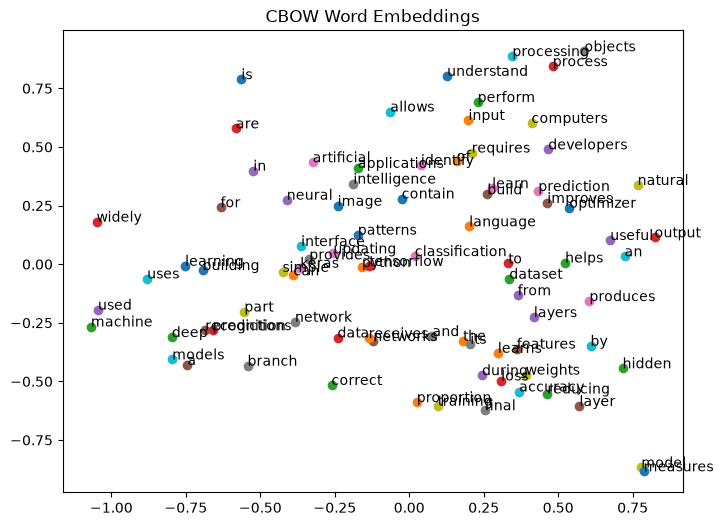

In [21]:
# Extract word embeddings
embeddings = model.get_weights()[0]

# Reduce embeddings to 2 dimensions
pca = PCA(n_components=2)
reduced = pca.fit_transform(embeddings)

# Plot embeddings
plt.figure(figsize=(8, 6))

for word, index in tokenizer.word_index.items():
    x, y = reduced[index]
    plt.scatter(x, y)
    plt.annotate(word, (x, y))

plt.title("CBOW Word Embeddings")
plt.show()

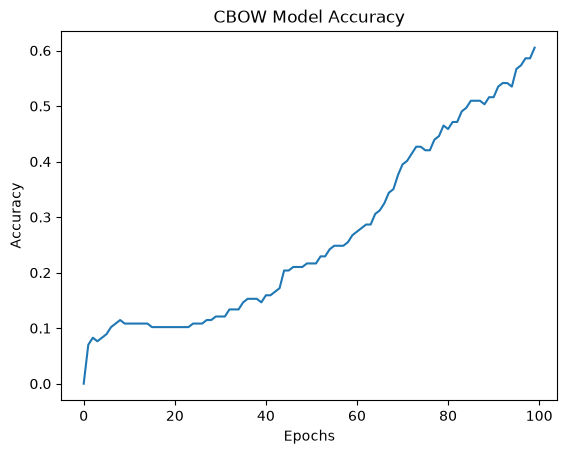

In [25]:
plt.plot(history.history['accuracy'])
plt.title('CBOW Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

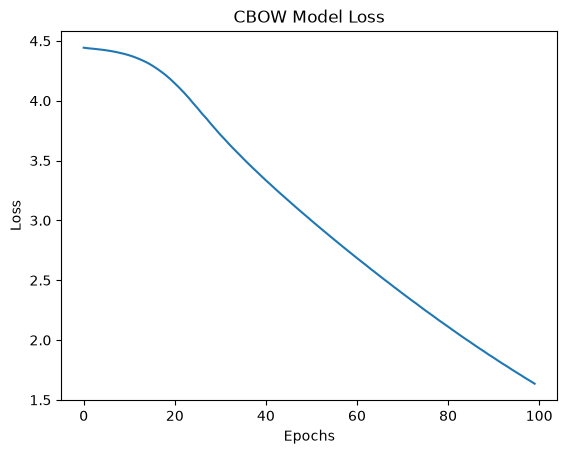

In [26]:
plt.plot(history.history['loss'])
plt.title('CBOW Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

In [35]:
context = X[0].reshape(1, 4)

prediction = model.predict(context, verbose=0)

predicted_index = np.argmax(prediction)

predicted_word = tokenizer.index_word.get(
    predicted_index, "Unknown"
)

actual_word = tokenizer.index_word.get(
    Y[0], "Unknown"
)

print("Context words:")

for index in X[0]:
    print(tokenizer.index_word.get(index, "Unknown"))

print("Actual target word:", actual_word)
print("Predicted target word:", predicted_word)

Context words:
deep
learning
a
branch
Actual target word: is
Predicted target word: is
